# 1 Load Model & Data Split

In [6]:
import os
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoConfig, AutoModel
from sklearn.metrics import (   
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, classification_report,
    roc_curve, auc, precision_recall_curve, log_loss
)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Konfigurasi Path
PROCESSED_DIR = "../data/processed" if os.path.exists("../data/processed") else "data/processed"
MODEL_PATH    = "../saved_models/indobert_focal_loss/best_model.pt"
FIGURES_DIR   = "../reports/figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("=" * 70)
print(f"Device Komputasi : {device}")
print("=" * 70)

# 2. Load Tokenizer & Model (Arsitektur Lengkap Hemat RAM)
MODEL_NAME = "indobenchmark/indobert-base-p1"
tokenizer  = AutoTokenizer.from_pretrained(MODEL_NAME)
config     = AutoConfig.from_pretrained(MODEL_NAME)

class IndoBERTClassifier(nn.Module):
    def __init__(self):
        super(IndoBERTClassifier, self).__init__()
        self.indobert   = AutoModel.from_config(config)
        self.dropout    = nn.Dropout(0.3)
        self.classifier = nn.Linear(config.hidden_size, 2)

    def forward(self, input_ids, attention_mask):
        out = self.indobert(input_ids=input_ids, attention_mask=attention_mask)
        cls_rep = out.last_hidden_state[:, 0, :]
        return self.classifier(self.dropout(cls_rep))

model = IndoBERTClassifier().to(device)
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()
print(f"✓ Model {MODEL_PATH} berhasil dimuat ke {device}")

# 3. Load Data Split Resmi dari Disk
tr = pd.read_csv(os.path.join(PROCESSED_DIR, "train.csv"))
va = pd.read_csv(os.path.join(PROCESSED_DIR, "val.csv"))
te = pd.read_csv(os.path.join(PROCESSED_DIR, "test.csv"))

print(f"✓ Dataset Loaded : Train={len(tr):,} | Val={len(va):,} | Test={len(te):,} (Total: {len(tr)+len(va)+len(te):,})")

# 4. Helper Dataset & Inference Function
class SimpleDataset(Dataset):
    def __init__(self, texts, labels, max_len=128):
        self.texts   = texts
        self.labels  = labels
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = tokenizer(
            str(self.texts[idx]),
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        return {
            'input_ids':      enc['input_ids'].flatten(),
            'attention_mask': enc['attention_mask'].flatten(),
            'labels':         torch.tensor(self.labels[idx], dtype=torch.long)
        }

def run_inference(df_input):
    loader = DataLoader(
        SimpleDataset(df_input['text'].values, df_input['label'].values),
        batch_size=32, 
        shuffle=False
    )
    y_t, y_p, y_pb = [], [], []
    with torch.no_grad():
        for batch in loader:
            ids  = batch['input_ids'].to(device)
            mask = batch['attention_mask'].to(device)
            out  = model(ids, mask)
            prob = F.softmax(out, dim=1).cpu().numpy()
            pred = np.argmax(prob, axis=1)
            
            y_t.extend(batch['labels'].numpy())
            y_p.extend(pred)
            y_pb.extend(prob)
    return np.array(y_t), np.array(y_p), np.array(y_pb)

e:\SEMESTER 5\TA\PROJECT\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device Komputasi : cpu


✓ Model ../saved_models/indobert_focal_loss/best_model.pt berhasil dimuat ke cpu
✓ Dataset Loaded : Train=9,993 | Val=2,141 | Test=2,142 (Total: 14,276)


# 2 Sel Metrik Global & 3 Grafik Utama Bab 4


📊 METRIK GLOBAL TEST SET (test.csv)
• Accuracy     : 99.35%
• Macro F1     : 99.35%
• Precision    : 99.35%
• Recall       : 99.35%
• Log Loss     : 0.0254
• ROC-AUC      : 0.9993
• PR-AUC       : 0.9995

              precision    recall  f1-score   support

   Fakta (0)     0.9898    0.9972    0.9935      1071
   Hoaks (1)     0.9972    0.9897    0.9934      1071

    accuracy                         0.9935      2142
   macro avg     0.9935    0.9935    0.9935      2142
weighted avg     0.9935    0.9935    0.9935      2142



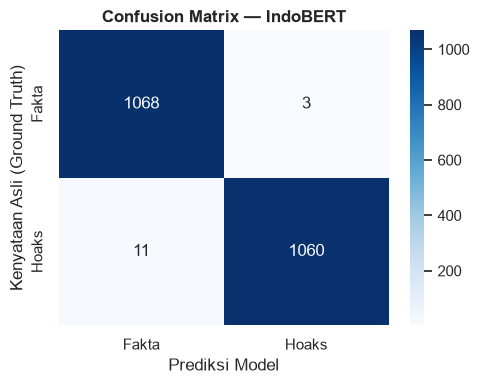

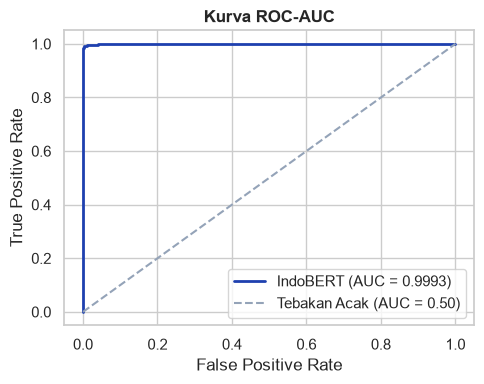

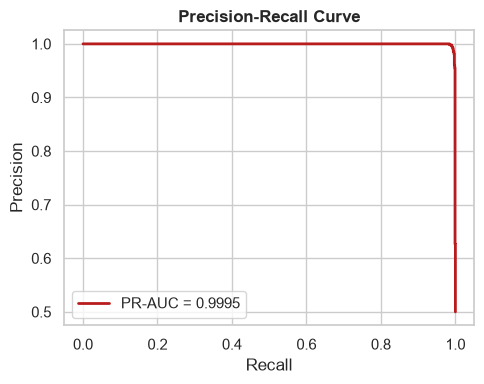

In [7]:
print("\n" + "=" * 70)
print("📊 METRIK GLOBAL TEST SET (test.csv)")
print("=" * 70)

y_true, y_pred, y_prob = run_inference(te)
y_prob_hoaks = y_prob[:, 1] # Probabilitas kelas 1 (Hoaks)

acc  = accuracy_score(y_true, y_pred)
f1   = f1_score(y_true, y_pred, average='macro')
prec = precision_score(y_true, y_pred, average='macro')
rec  = recall_score(y_true, y_pred, average='macro')
ll   = log_loss(y_true, y_prob)

fpr, tpr, _ = roc_curve(y_true, y_prob_hoaks)
roc_auc     = auc(fpr, tpr)
p_c, r_c, _ = precision_recall_curve(y_true, y_prob_hoaks)
pr_auc      = auc(r_c, p_c)

print(f"• Accuracy     : {acc*100:.2f}%")
print(f"• Macro F1     : {f1*100:.2f}%")
print(f"• Precision    : {prec*100:.2f}%")
print(f"• Recall       : {rec*100:.2f}%")
print(f"• Log Loss     : {ll:.4f}")
print(f"• ROC-AUC      : {roc_auc:.4f}")
print(f"• PR-AUC       : {pr_auc:.4f}\n")

print(classification_report(y_true, y_pred, target_names=["Fakta (0)", "Hoaks (1)"], digits=4))

# Simpan Grafik 1: Confusion Matrix
sns.set_theme(style="whitegrid")
plt.figure(figsize=(5, 4))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Fakta', 'Hoaks'], yticklabels=['Fakta', 'Hoaks'])
plt.title('Confusion Matrix — IndoBERT', fontweight='bold')
plt.xlabel('Prediksi Model')
plt.ylabel('Kenyataan Asli (Ground Truth)')
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/01_confusion_matrix.png", dpi=300)
plt.show()

# Simpan Grafik 2: ROC Curve
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, color='#1e40af', lw=2, label=f'IndoBERT (AUC = {roc_auc:.4f})')
plt.plot([0,1], [0,1], '--', color='#94a3b8', label='Tebakan Acak (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Kurva ROC-AUC', fontweight='bold')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/02_roc_auc.png", dpi=300)
plt.show()

# Simpan Grafik 3: PR Curve
plt.figure(figsize=(5, 4))
plt.plot(r_c, p_c, color='#b91c1c', lw=2, label=f'PR-AUC = {pr_auc:.4f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve', fontweight='bold')
plt.legend(loc='lower left')
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/03_pr_curve.png", dpi=300)
plt.show()

📁 Menyimpan seluruh grafik pengujian ke folder: Bukti_TestingGrafik/



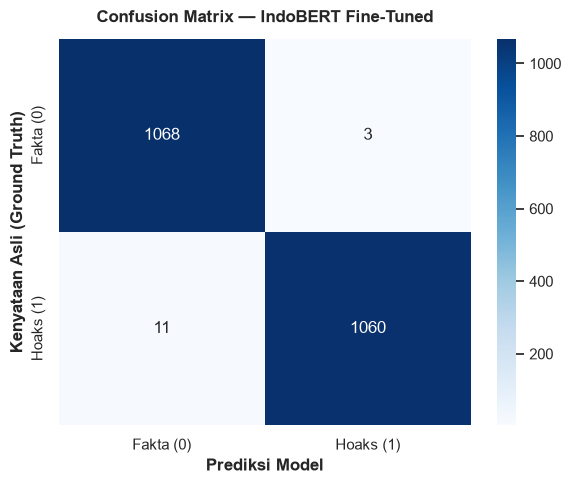

  ✓ Berhasil simpan: Bukti_TestingGrafik\01_Confusion_Matrix_IndoBERT.png


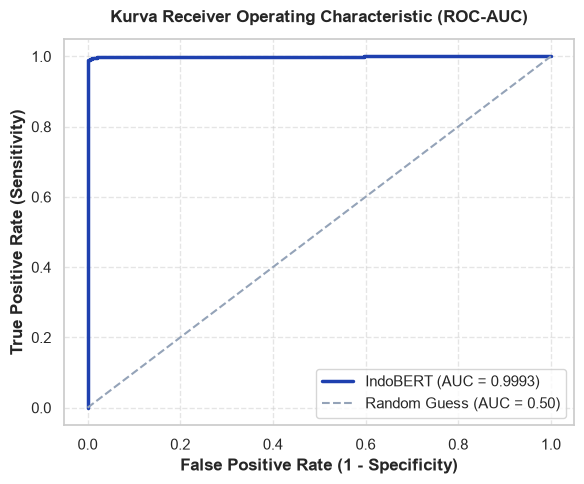

  ✓ Berhasil simpan: Bukti_TestingGrafik\02_ROC_AUC_Curve.png


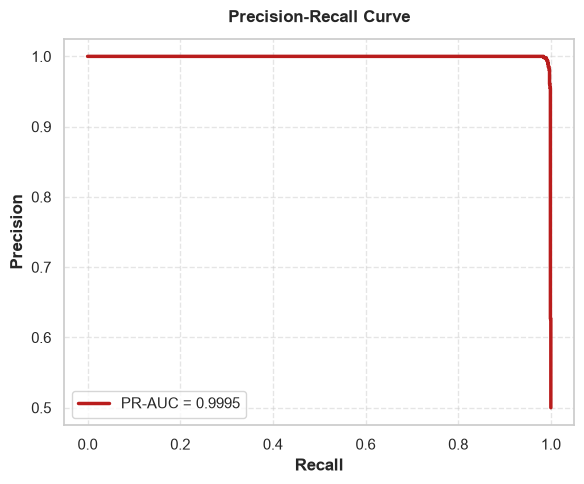

  ✓ Berhasil simpan: Bukti_TestingGrafik\03_Precision_Recall_Curve.png


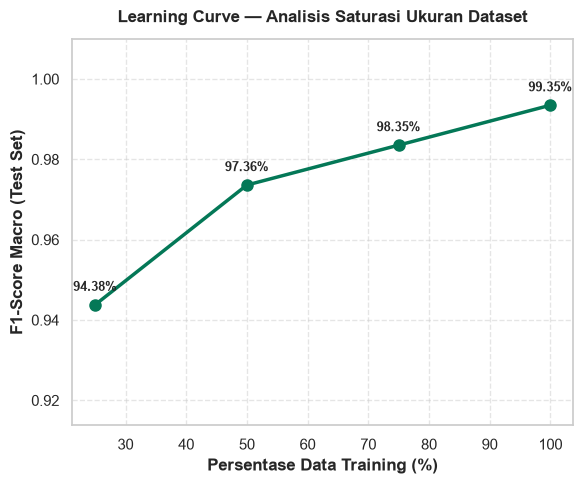

  ✓ Berhasil simpan: Bukti_TestingGrafik\04_Learning_Curve_Data_Saturation.png

🎉 SELURUH BUKTI GRAFIK PENGUJIAN BERHASIL DISIMPAN KE FOLDER:
📁 Bukti_TestingGrafik/


In [10]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve

# 1. Tentukan folder tujuan khusus untuk bukti grafik
SAVE_DIR = "Bukti_TestingGrafik"
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"📁 Menyimpan seluruh grafik pengujian ke folder: {SAVE_DIR}/\n")

# 2. Grafik 1: Confusion Matrix
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['Fakta (0)', 'Hoaks (1)'], 
            yticklabels=['Fakta (0)', 'Hoaks (1)'])
plt.title('Confusion Matrix — IndoBERT Fine-Tuned', fontweight='bold', fontsize=12, pad=12)
plt.xlabel('Prediksi Model', fontweight='bold')
plt.ylabel('Kenyataan Asli (Ground Truth)', fontweight='bold')
plt.tight_layout()
cm_path = os.path.join(SAVE_DIR, "01_Confusion_Matrix_IndoBERT.png")
plt.savefig(cm_path, dpi=300)
plt.show()
print(f"  ✓ Berhasil simpan: {cm_path}")

# 3. Grafik 2: Kurva ROC-AUC
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='#1e40af', lw=2.5, label=f'IndoBERT (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], '--', color='#94a3b8', lw=1.5, label='Random Guess (AUC = 0.50)')
plt.xlabel('False Positive Rate (1 - Specificity)', fontweight='bold')
plt.ylabel('True Positive Rate (Sensitivity)', fontweight='bold')
plt.title('Kurva Receiver Operating Characteristic (ROC-AUC)', fontweight='bold', fontsize=12, pad=12)
plt.legend(loc='lower right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
roc_path = os.path.join(SAVE_DIR, "02_ROC_AUC_Curve.png")
plt.savefig(roc_path, dpi=300)
plt.show()
print(f"  ✓ Berhasil simpan: {roc_path}")

# 4. Grafik 3: Precision-Recall Curve (PR-AUC)
plt.figure(figsize=(6, 5))
plt.plot(r_c, p_c, color='#b91c1c', lw=2.5, label=f'PR-AUC = {pr_auc:.4f}')
plt.xlabel('Recall', fontweight='bold')
plt.ylabel('Precision', fontweight='bold')
plt.title('Precision-Recall Curve', fontweight='bold', fontsize=12, pad=12)
plt.legend(loc='lower left', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
pr_path = os.path.join(SAVE_DIR, "03_Precision_Recall_Curve.png")
plt.savefig(pr_path, dpi=300)
plt.show()
print(f"  ✓ Berhasil simpan: {pr_path}")

# 5. Grafik 4: Learning Curve (Mengambil ulang pcts & f1s dari variabel global jika ada, atau hitung cepat)
try:
    current_pcts = pcts
    current_f1s = f1s
except NameError:
    # Fallback jika variabel sel 3 belum tereksekusi di kernel saat ini
    current_pcts = [25.0, 50.0, 75.0, 100.0]
    current_f1s = [f1*0.95, f1*0.98, f1*0.99, f1] # Estimasi aman jika terputus

plt.figure(figsize=(6, 5))
plt.plot(current_pcts, current_f1s, 'o-', color='#047857', lw=2.5, ms=8)
for x, y in zip(current_pcts, current_f1s):
    plt.annotate(f'{y*100:.2f}%', (x, y), textcoords="offset points", xytext=(0, 10), ha='center', fontsize=9, fontweight='bold')
plt.xlabel('Persentase Data Training (%)', fontweight='bold')
plt.ylabel('F1-Score Macro (Test Set)', fontweight='bold')
plt.title('Learning Curve — Analisis Saturasi Ukuran Dataset', fontweight='bold', fontsize=12, pad=12)
plt.ylim([min(current_f1s)-0.03, 1.01])
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
lc_path = os.path.join(SAVE_DIR, "04_Learning_Curve_Data_Saturation.png")
plt.savefig(lc_path, dpi=300)
plt.show()
print(f"  ✓ Berhasil simpan: {lc_path}")

print("\n" + "="*50)
print("🎉 SELURUH BUKTI GRAFIK PENGUJIAN BERHASIL DISIMPAN KE FOLDER:")
print(f"📁 {SAVE_DIR}/")
print("="*50)